# BIST Portfolio Tracker

Tracks a Borsa Istanbul equity portfolio against the **BIST 100** index, in both **TRY and USD**.

**Steps in this notebook**
1. Load the holdings (which stocks, how many shares, when bought)
2. Download daily prices from Yahoo Finance
3. Build a *time-weighted* performance index
4. Compare with BIST 100 in TRY and USD
5. Risk metrics: volatility, Sharpe ratio, max drawdown, beta
6. Charts and an Excel report

> The sample holdings are **example positions**, not real investments.
> If Yahoo Finance cannot be reached, the code falls back to **simulated** prices so it still runs.

In [1]:
# Install the packages this project needs (only slow the first time)
%pip install -q -r requirements.txt

## 0. Settings

In [2]:
# Import the project's own functions (tracker.py, in the same folder)
import pandas as pd
import tracker as tr

# Show numbers with 3 decimals and thousands separators
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

HOLDINGS_FILE = tr.DATA_DIR / "holdings_sample.csv"   # change to your own CSV
RISK_FREE_TRY = 0.0    # annual TRY risk-free rate, e.g. 0.35 = 35% (check the current TCMB rate)
OFFLINE = False        # True = use simulated prices, no internet needed
# Data sources, tried in this order; a later source fills gaps left by an earlier one
SOURCES = ["yahoo", "borsapy", "isyatirim"]

## 1. Holdings
Each row is one position. If `buy_price` is empty, the closing price on `buy_date` is used.

In [3]:
holdings = tr.load_holdings(HOLDINGS_FILE)
holdings

,ticker,sector,shares,amount_try,buy_price,buy_date,yahoo
0,THYAO,Transport,NaN,60000,NaN,2024-01-03,THYAO.IS
1,PGSUS,Transport,NaN,30000,NaN,2024-01-03,PGSUS.IS
2,ASELS,Defence,NaN,50000,NaN,2024-01-03,ASELS.IS
3,TUPRS,Energy,NaN,50000,NaN,2024-01-03,TUPRS.IS
4,KCHOL,Holding,NaN,60000,NaN,2024-01-03,KCHOL.IS
5,SAHOL,Holding,NaN,40000,NaN,2024-01-03,SAHOL.IS
6,GARAN,Banking,NaN,50000,NaN,2024-01-03,GARAN.IS
7,AKBNK,Banking,NaN,40000,NaN,2024-01-03,AKBNK.IS
8,YKBNK,Banking,NaN,30000,NaN,2024-03-01,YKBNK.IS
9,BIMAS,Retail,NaN,50000,NaN,2024-01-03,BIMAS.IS


## 2. Prices
We download the stocks, the BIST 100 index (`XU100.IS`) and the USD/TRY rate (`TRY=X`).

The code tries **Yahoo Finance** first. If a series is missing, it tries **borsapy** (TradingView / doviz.com) and then **İş Yatırım** (`isyatirimhisse`). The printed source line shows where each series came from.

In [4]:
tickers = list(holdings["yahoo"]) + [tr.BENCHMARK, tr.FX_TICKER]
prices = tr.get_prices(tickers, start=holdings["buy_date"].min(), offline=OFFLINE,
                       sources=SOURCES)
source = prices.attrs.get("source", "")
print("Price source:", source)

holdings = tr.fill_buy_prices(holdings, prices)   # fill empty buy prices
prices.tail()

yahoo: got 17 of 17 series
Price source: yahoo (AKBNK.IS, ASELS.IS, BIMAS.IS, EREGL.IS, FROTO.IS, GARAN.IS, KCHOL.IS, MGROS.IS, PGSUS.IS, SAHOL.IS, SISE.IS, TCELL.IS, THYAO.IS, TRY=X, TUPRS.IS, XU100.IS, YKBNK.IS)


Ticker,THYAO.IS,PGSUS.IS,ASELS.IS,TUPRS.IS,KCHOL.IS,SAHOL.IS,GARAN.IS,AKBNK.IS,YKBNK.IS,BIMAS.IS,MGROS.IS,EREGL.IS,SISE.IS,FROTO.IS,TCELL.IS,XU100.IS,TRY=X
Date,,,,,,,,,,,,,,,,,
2026-10-14,279.250,129.700,348.000,391.000,211.200,84.750,130.500,67.100,35.940,408.000,484.750,37.100,37.420,71.850,98.300,"12,118.300",49.342
2026-10-15,276.750,129.400,351.000,384.500,210.900,85.350,133.900,68.000,36.300,401.500,470.000,37.400,37.260,70.750,97.850,"12,070.200",49.405
2026-10-16,273.500,127.700,340.250,375.500,204.000,85.300,131.500,66.850,35.700,381.000,452.250,36.260,36.160,69.300,96.800,"11,721.700",49.523
2026-10-19,266.000,127.700,322.250,356.750,202.900,85.550,132.500,67.150,36.100,371.000,451.750,35.620,35.500,66.800,96.200,"11,430.100",49.523
2026-10-20,267.000,128.600,333.500,363.000,203.200,87.800,132.100,66.700,35.880,382.750,462.500,36.580,35.860,67.700,95.900,"11,621.280",NaN


## 3. Current positions
Market value, profit/loss and weight of each stock today.

In [5]:
table = tr.holdings_table(holdings, prices)
table

,ticker,sector,shares,buy_price,cost,last_price,market_value,pnl,pnl_pct,weight
0,ASELS,Defence,"1,076.000",46.460,"49,990.960",333.500,"358,846.000","308,855.040",6.178,0.254
1,TUPRS,Energy,474.000,105.440,"49,978.560",363.000,"172,062.000","122,083.440",2.443,0.122
2,BIMAS,Retail,361.000,138.280,"49,919.080",382.750,"138,172.750","88,253.670",1.768,0.098
3,GARAN,Banking,998.000,50.080,"49,979.840",132.100,"131,835.806","81,855.966",1.638,0.093
4,KCHOL,Holding,487.000,123.010,"59,905.870",203.200,"98,958.399","39,052.529",0.652,0.070
5,AKBNK,Banking,"1,246.000",32.100,"39,996.600",66.700,"83,108.196","43,111.596",1.078,0.059
6,EREGL,Materials,"2,005.000",19.950,"39,999.750",36.580,"73,342.904","33,343.154",0.834,0.052
7,THYAO,Transport,266.000,224.780,"59,791.480",267.000,"71,022.000","11,230.520",0.188,0.050
8,SAHOL,Holding,738.000,54.160,"39,970.080",87.800,"64,796.402","24,826.322",0.621,0.046
9,YKBNK,Banking,"1,391.000",21.560,"29,989.960",35.880,"49,909.081","19,919.121",0.664,0.035


## 4. Performance in TRY and USD
**Why a time-weighted index?** The stocks were bought on different dates. Each purchase adds new money,
which would make the portfolio value jump even though no return was earned. The time-weighted return removes these cash flows.

**Why USD?** With high inflation and a weakening lira, a positive TRY return can still be a loss in USD terms.
Looking at both gives a fairer picture.

In [6]:
# Time-weighted index of the portfolio, and the benchmark, in TRY
value_try = tr.portfolio_index(holdings, prices)
bench_try = prices[tr.BENCHMARK].ffill().rename("BIST 100")

# Same series converted to USD with the daily USD/TRY rate
value_usd = tr.to_usd(value_try, prices[tr.FX_TICKER])
bench_usd = tr.to_usd(bench_try, prices[tr.FX_TICKER])

metrics = pd.DataFrame({
    "TRY": tr.performance_metrics(value_try, bench_try, RISK_FREE_TRY),
    "USD": tr.performance_metrics(value_usd, bench_usd, 0.0),
})
metrics

,TRY,USD
Start date,2024-01-03,2024-01-03
End date,2026-10-20,2026-10-20
Total return,1.363,0.419
Benchmark return,0.568,-0.058
Excess return,0.795,0.477
CAGR,0.347,0.129
Annual volatility,0.257,0.262
Sharpe ratio,1.289,0.594
Max drawdown,-0.196,-0.255
Benchmark max drawdown,-0.245,-0.322


**How to read the metrics**
- **CAGR**: average yearly growth rate.
- **Annual volatility**: how much returns swing (higher = riskier).
- **Sharpe ratio**: return above the risk-free rate per unit of risk. Above 1 is good.
- **Max drawdown**: the worst fall from a previous peak.
- **Beta**: 1.0 = moves like BIST 100; above 1 = moves more than the index.
- **Information ratio**: excess return over BIST 100 per unit of deviation from it.

## 5. Charts

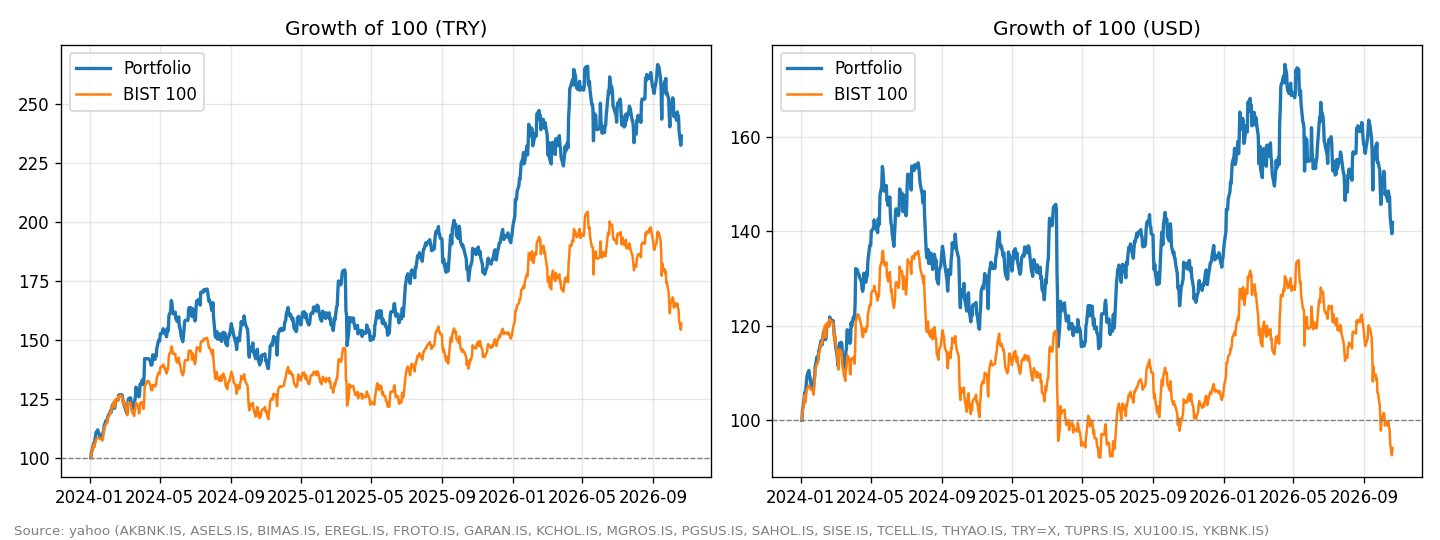

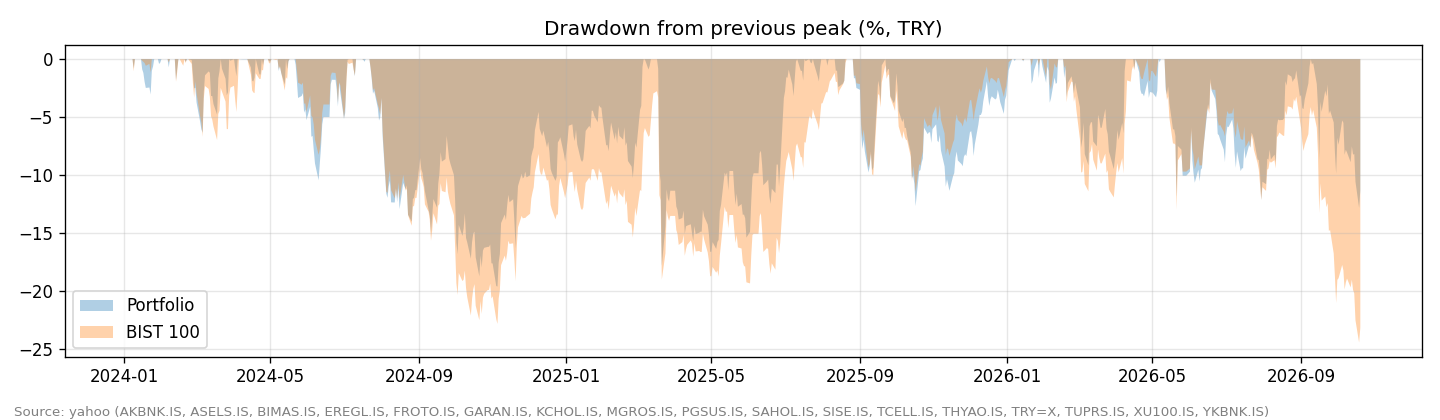

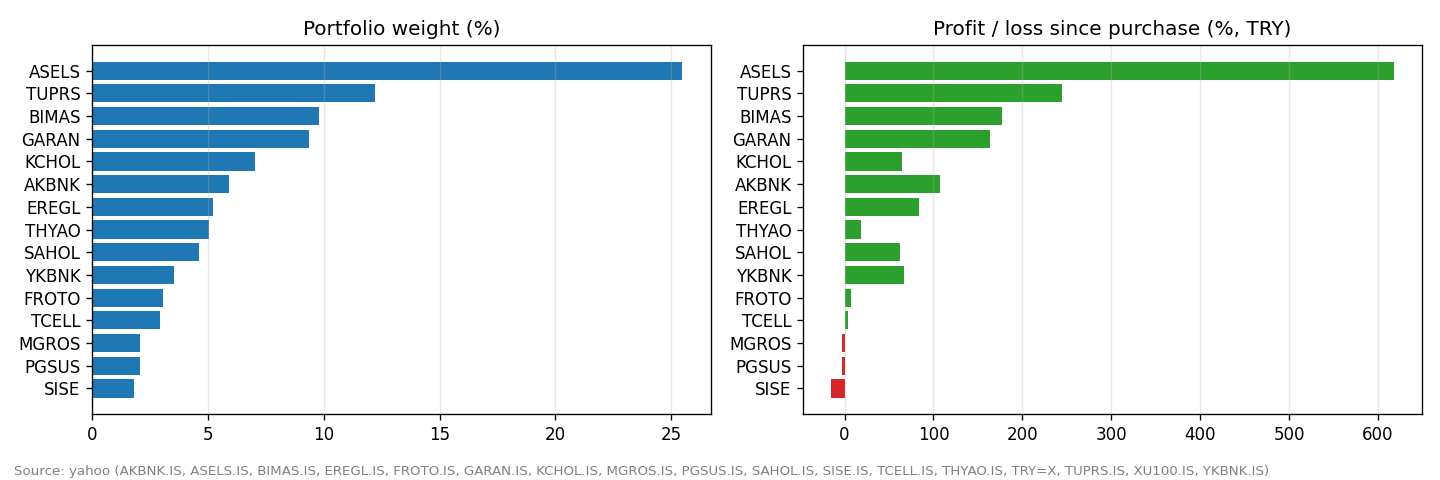

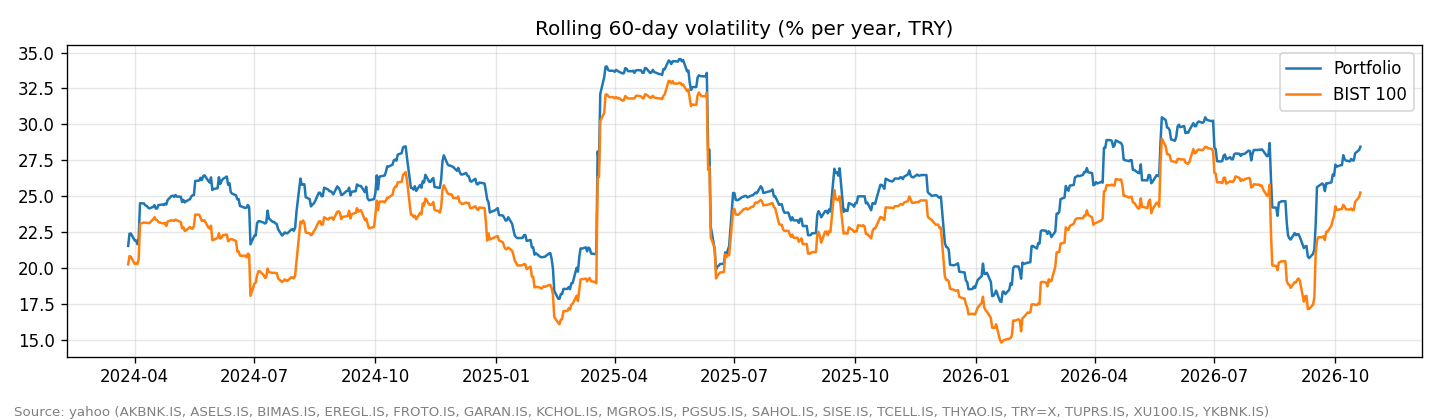

In [7]:
from IPython.display import Image, display

out_dir = tr.PROJECT_DIR / "output"
chart_files = tr.make_charts(value_try, bench_try, value_usd, bench_usd, table, out_dir, source)
for path in chart_files:
    display(Image(filename=str(path)))

## 6. Excel report
The **Holdings** sheet uses Excel formulas, so you can type a new price into a blue cell and the totals update.

In [8]:
report = tr.export_excel(table, metrics["TRY"], metrics["USD"], value_try, bench_try,
                         out_dir / "portfolio_report.xlsx", source)
print("Saved:", report.relative_to(tr.PROJECT_DIR))

Saved: output/portfolio_report.xlsx


## Possible next steps
- Add dividends (total return instead of price return)
- Compare against an inflation-adjusted (real) return using Turkish CPI
- Rebalancing rules, e.g. keep each stock below 25% weight